In [4]:
import pandas as pd
state_data = pd.read_csv("F26_cf_demo_data.csv")
state_data.shape

(50, 2)

In [9]:
print(state_data.head())
print(state_data.tail())
print(state_data.head(1))
print(state_data.tail(1))

          x          y
0  0.000000   1.909918
1  0.204082   1.736152
2  0.408163   9.266035
3  0.612245   4.644937
4  0.816327  15.596592
            x           y
45   9.183673  113.130937
46   9.387755  109.902028
47   9.591837  119.716504
48   9.795918  123.796965
49  10.000000  123.740302
     x         y
0  0.0  1.909918
       x           y
49  10.0  123.740302


In [13]:
state_data[["x", "y"]].median()

x     5.000000
y    51.185221
dtype: float64

In [15]:
median_longitude = state_data["x"].median()
state_data["distance_to_median"] = (state_data["x"] - median_longitude).abs()
state_data.head()

,x,y,distance_to_median
0,0.000000,1.909918,5.000000
1,0.204082,1.736152,4.795918
2,0.408163,9.266035,4.591837
3,0.612245,4.644937,4.387755
4,0.816327,15.596592,4.183673


In [16]:
state_data.shape

(50, 3)

In [35]:
median_latitude = state_data["y"].median()
state_data["latitude_distance"] = (state_data["y"] - median_latitude).abs()
closest_state_lat = state_data.loc[state_data["latitude_distance"].idxmin()]
print(f"Closest state:{closest_state_lat['latitude_distance']: .2f}")

Closest state: 4.16


In [34]:
median_latitude = state_data["y"].median()
state_data["latitude_distance"] = (state_data["y"] - median_latitude).abs()
farthest_state_lat = state_data.loc[state_data["latitude_distance"].idxmax()]
print(f"Farthest state:{farthest_state_lat['latitude_distance']: .2f}")

Farthest state: 72.61


In [33]:
median_longitude = state_data["x"].median()
state_data["longitude_distance"] = (state_data["x"] - median_longitude).abs()
closest_state_long = state_data.loc[state_data["longitude_distance"].idxmin()]
print(f"Closest state:{closest_state_long['longitude_distance']: .2f}")

Closest state: 0.10


In [32]:
median_longitude = state_data["x"].median()
state_data["longitude_distance"] = (state_data["x"] - median_longitude).abs()
farthest_state_long = state_data.loc[state_data["longitude_distance"].idxmax()]
print(f"Farthest state:{farthest_state_long['longitude_distance']: .2f}")

Farthest state: 5.00


In [39]:
merged_df = pd.DataFrame({
    "Median Latitude": [median_latitude],
    "Median Longitude": [median_longitude]
})

merged_df
# merges two data sets, helpful for example to see lat and long displayed at the same time

,Median Latitude,Median Longitude
0,51.185221,5.0


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

anagrams_df = sns.load_dataset("anagrams")
anagrams_df

,subidr,attnr,num1,num2,num3
0,1,divided,2,4.0,7
1,2,divided,3,4.0,5
2,3,divided,3,5.0,6
3,4,divided,5,7.0,5
4,5,divided,4,5.0,8
5,6,divided,5,5.0,6
6,7,divided,5,4.5,6
7,8,divided,5,7.0,8
8,9,divided,2,3.0,7
9,10,divided,6,5.0,6


In [50]:
anagrams_df = anagrams_df.dropna(axis=1)
anagrams_df

,subidr,attnr,num1,num2,num3
0,1,divided,2,4.0,7
1,2,divided,3,4.0,5
2,3,divided,3,5.0,6
3,4,divided,5,7.0,5
4,5,divided,4,5.0,8
5,6,divided,5,5.0,6
6,7,divided,5,4.5,6
7,8,divided,5,7.0,8
8,9,divided,2,3.0,7
9,10,divided,6,5.0,6


In [51]:
anagrams_df.shape

(20, 5)

In [52]:
anagrams_df.head()

,subidr,attnr,num1,num2,num3
0,1,divided,2,4.0,7
1,2,divided,3,4.0,5
2,3,divided,3,5.0,6
3,4,divided,5,7.0,5
4,5,divided,4,5.0,8


In [53]:
anagrams_df.tail()

,subidr,attnr,num1,num2,num3
15,16,focused,6,8.0,7
16,17,focused,7,7.0,6
17,18,focused,7,8.0,6
18,19,focused,5,6.0,6
19,20,focused,6,6.0,5


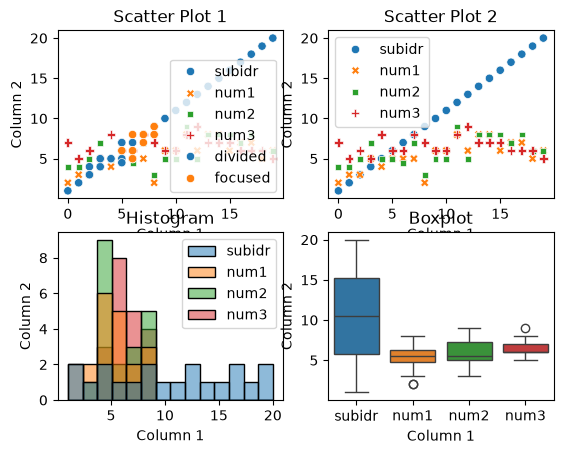

In [61]:
fig, axes = plt.subplots(2, 2)

sns.scatterplot(data=anagrams_df, ax=axes[0, 0])

sns.scatterplot(data=anagrams_df, ax=axes[0, 1])

sns.histplot(data=anagrams_df, ax=axes[1, 0])

sns.boxplot(data=anagrams_df, ax=axes[1, 1])

axes[0, 0].set_title("Scatter Plot 1")
axes[0, 1].set_title("Scatter Plot 2")
axes[1, 0].set_title("Histogram")
axes[1, 1].set_title("Boxplot")

axes[0, 0].set_xlabel("Column 1")
axes[0, 0].set_ylabel("Column 2")

axes[0, 1].set_xlabel("Column 1")
axes[0, 1].set_ylabel("Column 2")

axes[1, 0].set_xlabel("Column 1")
axes[1, 0].set_ylabel("Column 2")

axes[1, 1].set_xlabel("Column 1")
axes[1, 1].set_ylabel("Column 2")

sns.scatterplot(data=anagrams_df, x="num1", y="num2",
                hue="attnr", ax=axes[0, 0])

axes[0, 0].legend()

plt.show()